# SMOTE Experimentation

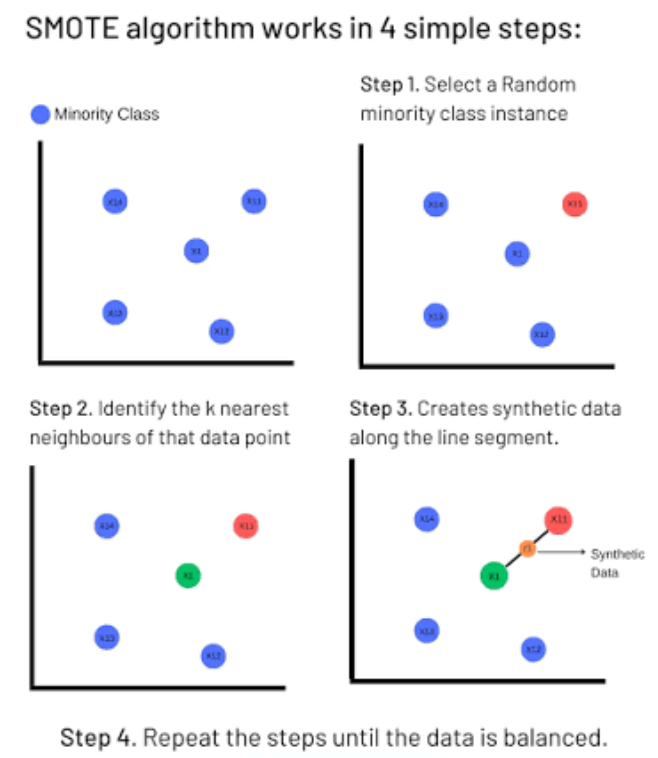

## Step 1 — Generating a Synthetic Sample

SMOTE (Chawla et al., 2002) creates new minority-class samples instead of simply duplicating existing ones.

It generates a sample between an existing minority observation and one of its nearest neighbours using interpolation.

The formula is:

$$
x_{\text{new}} = x_i + \lambda (x_{nn} - x_i)
$$

Here, $x_i$ is the original sample, $x_{nn}$ is its selected neighbour, and $\lambda$ is a random number between 0 and 1.

We'll use two simple points and a fixed value of 0.25 to understand the calculation before implementing the complete algorithm.

In [1]:
import numpy as np

# Original minority-class sample
x_i = np.array([6.0, 4.0])

# One of its minority-class nearest neighbours
x_nn = np.array([4.0, 3.0])

# Random interpolation factor for this example
gap = 0.25

# Generate a synthetic sample
x_new = x_i + gap * (x_nn - x_i)

print("Original sample:", x_i)
print("Selected neighbour:", x_nn)
print("Synthetic sample:", x_new)

Original sample: [6. 4.]
Selected neighbour: [4. 3.]
Synthetic sample: [5.5  3.75]


## Step 2 — Calculating Euclidean Distances

SMOTE finds the nearest neighbours of each minority-class sample before generating synthetic data.

We'll use **Euclidean distance**, which measures the straight-line distance between two points.

For two samples with two features, the formula is:

$$
d(A,B) = \sqrt{(A_1-B_1)^2 + (A_2-B_2)^2}
$$

A smaller distance means two samples are closer together.

We'll calculate the distance between one minority sample and the other minority samples. The sample itself will have a distance of zero, so we must exclude it when selecting neighbours.


In [2]:
# Four example minority-class samples
X_minority = np.array([
    [6.0, 4.0],
    [4.0, 3.0],
    [5.0, 1.0],
    [1.0, 2.0]
])

# Choose the first sample as our reference point
x_i = X_minority[0]

# Calculate its distance from every sample
for i, sample in enumerate(X_minority):
    difference = sample - x_i
    distance = np.sqrt(np.sum(difference ** 2))

    print(f"Sample {i}: {sample}, Distance = {distance:.3f}")

Sample 0: [6. 4.], Distance = 0.000
Sample 1: [4. 3.], Distance = 2.236
Sample 2: [5. 1.], Distance = 3.162
Sample 3: [1. 2.], Distance = 5.385


## Step 3 — Selecting the k Nearest Neighbours

Now that we can calculate distances, we need to identify the **k nearest neighbours** of a minority-class sample.

SMOTE uses these neighbours to decide where synthetic samples can be generated. A smaller distance means a sample is closer to our reference point.

We'll sort the distances in ascending order, exclude the reference sample itself, and select the nearest neighbours.

The original paper uses $k = 5$. Since our example contains only four samples in total, we'll use $k = 2$ to demonstrate the process. Our actual implementation will support a configurable number of neighbours.

*Reference: Chawla et al. (2002), Section 4.2.*

In [3]:
# Select the number of neighbours for this example
k = 2

# Choose the reference sample
sample_index = 0
x_i = X_minority[sample_index]

# Calculate distances from the reference sample
distances = np.sqrt(np.sum((X_minority - x_i) ** 2, axis=1))

# Exclude the reference sample itself
distances[sample_index] = np.inf

# Sort the sample indices by distance
nearest_indices = np.argsort(distances)[:k]

print("Reference sample:", x_i)
print("\nNearest neighbours:")

for index in nearest_indices:
    print(
        f"Sample {index}: {X_minority[index]}, "
        f"Distance = {distances[index]:.3f}"
    )

Reference sample: [6. 4.]

Nearest neighbours:
Sample 1: [4. 3.], Distance = 2.236
Sample 2: [5. 1.], Distance = 3.162


## Step 4 — Generating Multiple Synthetic Samples

Now that we can identify the nearest neighbours, we can combine everything to generate multiple synthetic samples.

For each new sample, SMOTE randomly selects one of the nearest minority-class neighbours and generates a random interpolation factor, $\lambda$, between 0 and 1.

The new sample is calculated as:

$$
x_{\text{new}} = x_i + \lambda (x_{nn} - x_i)
$$

We'll use our reference sample and its two nearest neighbours from the previous step to generate five synthetic samples.

The complete algorithm will repeat this process across minority-class samples to generate the required number of examples.

In [4]:
# Use a fixed seed so the results are reproducible
rng = np.random.default_rng(42)

# Number of synthetic samples to generate
n_synthetic = 5

synthetic_samples = []

for i in range(n_synthetic):

    # Randomly select one of the nearest neighbours
    neighbor_index = rng.choice(nearest_indices)
    x_nn = X_minority[neighbor_index]

    # Choose a random interpolation factor between 0 and 1
    gap = rng.random()

    # Generate the synthetic sample
    x_new = x_i + gap * (x_nn - x_i)

    synthetic_samples.append(x_new)

    print(
        f"Sample {i + 1}: "
        f"Neighbour {neighbor_index}, "
        f"Gap = {gap:.3f}, "
        f"New sample = {np.round(x_new, 3)}"
    )

# Convert the generated samples into a NumPy array
synthetic_samples = np.array(synthetic_samples)

print("\nSynthetic samples shape:", synthetic_samples.shape)

Sample 1: Neighbour 1, Gap = 0.439, New sample = [5.122 3.561]
Sample 2: Neighbour 2, Gap = 0.859, New sample = [5.141 1.424]
Sample 3: Neighbour 1, Gap = 0.094, New sample = [5.812 3.906]
Sample 4: Neighbour 2, Gap = 0.976, New sample = [5.024 1.073]
Sample 5: Neighbour 2, Gap = 0.786, New sample = [5.214 1.642]

Synthetic samples shape: (5, 2)


## Step 5 — Calculating the Number of Synthetic Samples

SMOTE allows us to control how much the minority class is oversampled.

In the original paper by Chawla et al. (2002), the oversampling percentage determines how many synthetic samples are generated relative to the original minority-class count.

If $T$ is the number of original minority samples and $N$ is the oversampling percentage, the number of synthetic samples is:

$$
N_{\text{synthetic}} = \frac{N}{100} \times T
$$

For example, if we have 100 minority samples, 200% oversampling generates 200 synthetic samples, giving us 300 minority samples in total.

We'll calculate these counts for our small example before implementing the complete sampling process.

In [5]:
# Number of original minority-class samples
T = len(X_minority)

# Oversampling percentages from the original paper's notation
percentages = [100, 200, 300, 500]

for N in percentages:
    n_synthetic = int((N / 100) * T)
    total_minority = T + n_synthetic

    print(
        f"Oversampling: {N}% | "
        f"Synthetic samples: {n_synthetic} | "
        f"Final minority count: {total_minority}"
    )

Oversampling: 100% | Synthetic samples: 4 | Final minority count: 8
Oversampling: 200% | Synthetic samples: 8 | Final minority count: 12
Oversampling: 300% | Synthetic samples: 12 | Final minority count: 16
Oversampling: 500% | Synthetic samples: 20 | Final minority count: 24


## Step 6 — Generating Samples Across the Minority Class

So far, we've generated synthetic samples using a single reference observation. In the complete SMOTE process, we repeat this procedure across minority-class observations to generate the required number of samples.

For each selected minority sample, we find its nearest minority-class neighbours, randomly select a neighbour, and interpolate between the two observations.

We'll now combine our earlier steps to generate synthetic samples across the entire minority dataset.

For this demonstration, we'll generate one synthetic sample per original minority sample. This corresponds to 100% oversampling when the minority samples are processed once each.

The generated samples will then be combined with the original minority samples.

In [6]:
# Reproducible random number generator
rng = np.random.default_rng(42)

# Number of neighbours used in our example
k = 2

# Number of synthetic samples to generate
n_synthetic = len(X_minority)

synthetic_samples = []

for sample_index, x_i in enumerate(X_minority):

    # Calculate distances from this sample to all minority samples
    distances = np.sqrt(
        np.sum((X_minority - x_i) ** 2, axis=1)
    )

    # Exclude the sample itself
    distances[sample_index] = np.inf

    # Find its k nearest neighbours
    nearest_indices = np.argsort(distances)[:k]

    # Randomly choose one of those neighbours
    neighbor_index = rng.choice(nearest_indices)
    x_nn = X_minority[neighbor_index]

    # Generate a random interpolation factor
    gap = rng.random()

    # Create the synthetic sample
    x_new = x_i + gap * (x_nn - x_i)

    synthetic_samples.append(x_new)

# Convert generated samples into a NumPy array
synthetic_samples = np.array(synthetic_samples)

# Combine original and synthetic minority samples
X_minority_resampled = np.vstack([
    X_minority,
    synthetic_samples
])

print("Original minority samples:", X_minority.shape)
print("Synthetic samples:", synthetic_samples.shape)
print("Resampled minority samples:", X_minority_resampled.shape)

Original minority samples: (4, 2)
Synthetic samples: (4, 2)
Resampled minority samples: (8, 2)



## Step 7 — Testing Our SMOTE Implementation

We'll test our class on a small, labelled dataset containing both majority and minority examples.

The minority class should receive enough synthetic samples to match the majority-class count. The original observations and their labels should remain unchanged.


In [7]:

import numpy as np
from smote_from_scratch.sampler import SMOTE

# Eight majority-class samples and four minority-class samples.
X = np.array([
    [1.0, 1.0],
    [1.5, 1.2],
    [2.0, 1.0],
    [2.5, 1.5],
    [3.0, 2.0],
    [3.5, 2.5],
    [4.0, 3.0],
    [4.5, 3.5],
    [6.0, 4.0],
    [4.0, 3.0],
    [5.0, 1.0],
    [1.0, 2.0]
])

y = np.array([0] * 8 + [1] * 4)

smote = SMOTE(k_neighbors=2, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("Original dataset shape:", X.shape)
print("Resampled dataset shape:", X_resampled.shape)
print("\nOriginal class counts:", np.unique(y, return_counts=True))
print("Resampled class counts:", np.unique(y_resampled, return_counts=True))
print("\nSynthetic samples:\n", X_resampled[len(X):])


Original dataset shape: (12, 2)
Resampled dataset shape: (16, 2)

Original class counts: (array([0, 1]), array([8, 4]))
Resampled class counts: (array([0, 1]), array([8, 8]))

Synthetic samples:
 [[5.56112156 2.68336468]
 [4.69736803 1.60526394]
 [4.0487553  3.02437765]
 [5.78606431 3.35819292]]
